fine tuning ModernBERT 

In [2]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed
)
from peft import LoraConfig, TaskType, get_peft_model #for LoRA
import torch
import os
import numpy as np
import pandas as pd
from transformers import DataCollatorWithPadding
from datasets import DatasetDict, Dataset
set_seed(42)



# Auto-detect Apple Silicon GPU (MPS), CUDA, or CPU
device = torch.device(
    'mps'
    if torch.backends.mps.is_available()
    else ('cuda' if torch.cuda.is_available() else 'cpu')
)
print(f'Execution Device: {device}')




/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Execution Device: mps


In [3]:
DATA_DIR = '../../data/processed/splits'

train_df = pd.read_csv(f'{DATA_DIR}/train_text.csv')
val_df = pd.read_csv(f'{DATA_DIR}/val_text.csv')
test_df = pd.read_csv(f'{DATA_DIR}/test_text.csv')

print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')


Train: 1561 | Val: 223 | Test: 447


TOKENISATION

In [4]:
MODEL_NAME = 'answerdotai/ModernBERT-base'
MAX_LENGTH = 128  # Covers 99%+ of queries based on EDA

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

raw_datasets = DatasetDict({
    'train': Dataset.from_pandas(train_df),
    'val': Dataset.from_pandas(val_df),
    'test': Dataset.from_pandas(test_df),
})


def tokenize_function(examples):
  return tokenizer(
      examples['question'], truncation=True, max_length=MAX_LENGTH
  )


# Remove raw 'question' string column so tensors can be padded by collator
tokenized_datasets = raw_datasets.map(
    tokenize_function, batched=True, remove_columns=['question']
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


Map: 100%|██████████| 447/447 [00:00<00:00, 34632.29 examples/s]


In [10]:
id2label = {0: 'Multi-hop', 1: 'Shortcut'}
label2id = {'Multi-hop': 0, 'Shortcut': 1}

base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id
)

# 2. Define the LoRA Configuration
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,                          # Halved capacity; ~1.5k examples doesn't need r=16
    lora_alpha=16,                # Keep alpha = 2 * r
    lora_dropout=0.1,             # Stronger regularization
    target_modules=["Wqkv", "Wo"],  # Attention only; dropped "Wi" (MLP) to cut capacity
    modules_to_save=["classifier"],
)

# 3. Apply LoRA to the model
model = get_peft_model(base_model, lora_config)

# Print trainable parameters to confirm it worked
model.print_trainable_parameters()

print(
    f'Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}'
)
# ~149 Million parameters


Some weights of ModernBertForSequenceClassification were not initialized from the model checkpoint at answerdotai/ModernBERT-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 1,150,466 || all params: 150,756,868 || trainable%: 0.7631
Trainable parameters: 1,150,466


In [11]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score


def compute_metrics(eval_pred):
  logits, labels = eval_pred
  preds = np.argmax(logits, axis=-1)

  # Softmax probabilities for ROC-AUC
  exp_logits = np.exp(logits - np.max(logits, axis=-1, keepdims=True))
  probs = exp_logits / np.sum(exp_logits, axis=-1, keepdims=True)

  precision, recall, f1, _ = precision_recall_fscore_support(
      labels, preds, average='binary', zero_division=0
  )
  acc = accuracy_score(labels, preds)
  try:
    auc = roc_auc_score(labels, probs[:, 1])
  except Exception:
    auc = 0.0

  return {
      'accuracy': round(acc, 4),
      'precision': round(precision, 4),
      'recall': round(recall, 4),
      'f1': round(f1, 4),
      'roc_auc': round(auc, 4),
  }


In [12]:
OUTPUT_DIR = './checkpoints_modernbert_base'

training_args = TrainingArguments(
    output_dir="./checkpoints_modernbert_lora_v2",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=8e-5,           # Down from 1.5e-4
    lr_scheduler_type="cosine",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,           # Val loss was best at epoch 1; 3 gives room to peak
    weight_decay=0.05,            # Up from 0.01
    warmup_ratio=0.1,
    max_grad_norm=1.0,
    label_smoothing_factor=0.1,   # Softens overconfident predictions
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",  # Loss was the clearer overfitting signal
    greater_is_better=False,
    save_total_limit=2,
    logging_steps=15,
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets['train'],
    eval_dataset=tokenized_datasets['val'],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# Launch fine-tuning
train_result = trainer.train()



/var/folders/08/lbty5k850dj31mxx5r7fngpc0000gn/T/ipykernel_40855/696316449.py:25: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': None, 'bos_token_id': None}.
/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc
1,0.619000,0.624973,0.663700,0.693900,0.601800,0.644500,0.730100
2,0.622200,0.611205,0.668200,0.663900,0.699100,0.681000,0.743000
3,0.558800,0.608200,0.677100,0.669400,0.716800,0.692300,0.747800


/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


               precision    recall  f1-score   support

Multi-hop (0)       0.74      0.67      0.71       220
 Shortcut (1)       0.71      0.78      0.74       227

     accuracy                           0.72       447
    macro avg       0.73      0.72      0.72       447
 weighted avg       0.73      0.72      0.72       447



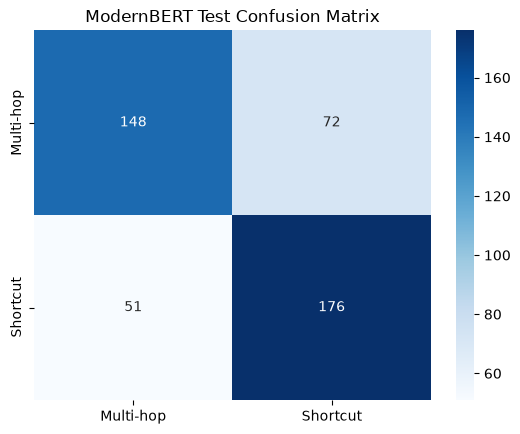

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve

# Evaluate on test set
test_pred = trainer.predict(tokenized_datasets['test'])
test_logits = test_pred.predictions
test_labels = test_pred.label_ids
test_preds = np.argmax(test_logits, axis=-1)

print(
    classification_report(
        test_labels, test_preds, target_names=['Multi-hop (0)', 'Shortcut (1)']
    )
)

# Plot Confusion Matrix
cm = confusion_matrix(test_labels, test_preds)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Multi-hop', 'Shortcut'],
    yticklabels=['Multi-hop', 'Shortcut'],
)
plt.title('ModernBERT Test Confusion Matrix')
plt.show()


In [9]:
# Save final model
SAVE_DIR = '../saved_models/modernbert_base_shortcut_detector'
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)


# Inference function
def predict_shortcut(query: str):
  model.eval()
  inputs = tokenizer(
      query, return_tensors='pt', truncation=True, max_length=128
  ).to(device)
  with torch.no_grad():
    logits = model(**inputs).logits
    probs = torch.softmax(logits, dim=-1).cpu().numpy()[0]
    pred = int(np.argmax(probs))
  return {
      'query': query,
      'prediction': id2label[pred],
      'confidence': float(probs[pred]),
      'prob_multihop': float(probs[0]),
      'prob_shortcut': float(probs[1]),
  }


# Test inference
print(
    predict_shortcut(
        "What is the software engineering manager's office room number for the team that built Project Orion?"
    )
)


{'query': "What is the software engineering manager's office room number for the team that built Project Orion?", 'prediction': 'Shortcut', 'confidence': 0.6705920100212097, 'prob_multihop': 0.3294079899787903, 'prob_shortcut': 0.6705920100212097}
